In [18]:
#Plotting library
import matplotlib.pyplot as plt

#Data library...like Excel for python
import pandas as pd

#Numerical function library
import numpy as np

#Operating system, 'glob' library - for getting list of files in directory
import os, glob

#Jupyter command for generating Matplotlib plots inline with the commands in the notebook
%matplotlib inline


import seaborn as sns
import scipy
import math
from IPython.display import set_matplotlib_formats
# matplotlib_inline.backend_inline.set_matplotlib_formats()
set_matplotlib_formats('retina')

# plt.style.use('seaborn-whitegrid')

#set the working directory (where the data you want to work up is stored)
topwd='/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20260806-3TT_TEST'

#change whatever the current working space is to the desired space, just set above
os.chdir(topwd)

#check that directory is right
os.getcwd()

/var/folders/v7/gxvkh6fs2bl1s2vfh9653l900000gr/T/ipykernel_35047/695485469.py:22: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  set_matplotlib_formats('retina')


'/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20260806-3TT_TEST'

In [19]:
# change font if you want
plt.rcParams['font.sans-serif'] = "Arial"
plt.rcParams['font.family'] = "sans-serif"

In [20]:
#glob will find anything with string given and put it into filelist
filelist = sorted(glob.glob('*.mpt'))
#filelist='20260723_3Tagsd200nmgrid_seedafter_RZ_CV_inital_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_1sun_after_cp1_cv1_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_dark_after_cp2_cv2_C01.mpt',
filelist

['20260806_3ttUN_FZ_dry_1sun_CV_C01.mpt',
 '20260806_3ttUN_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_RZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C02.mpt',
 '20260806_MW736n2_RZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n2_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n2_Tz_dry_1sun_CV_C01.mpt']

In [5]:
#glob will find anything with string given and put it into filelist
filelist = sorted(glob.glob('*cp9*.mpt'))
filelist = '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt', '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt', '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt',


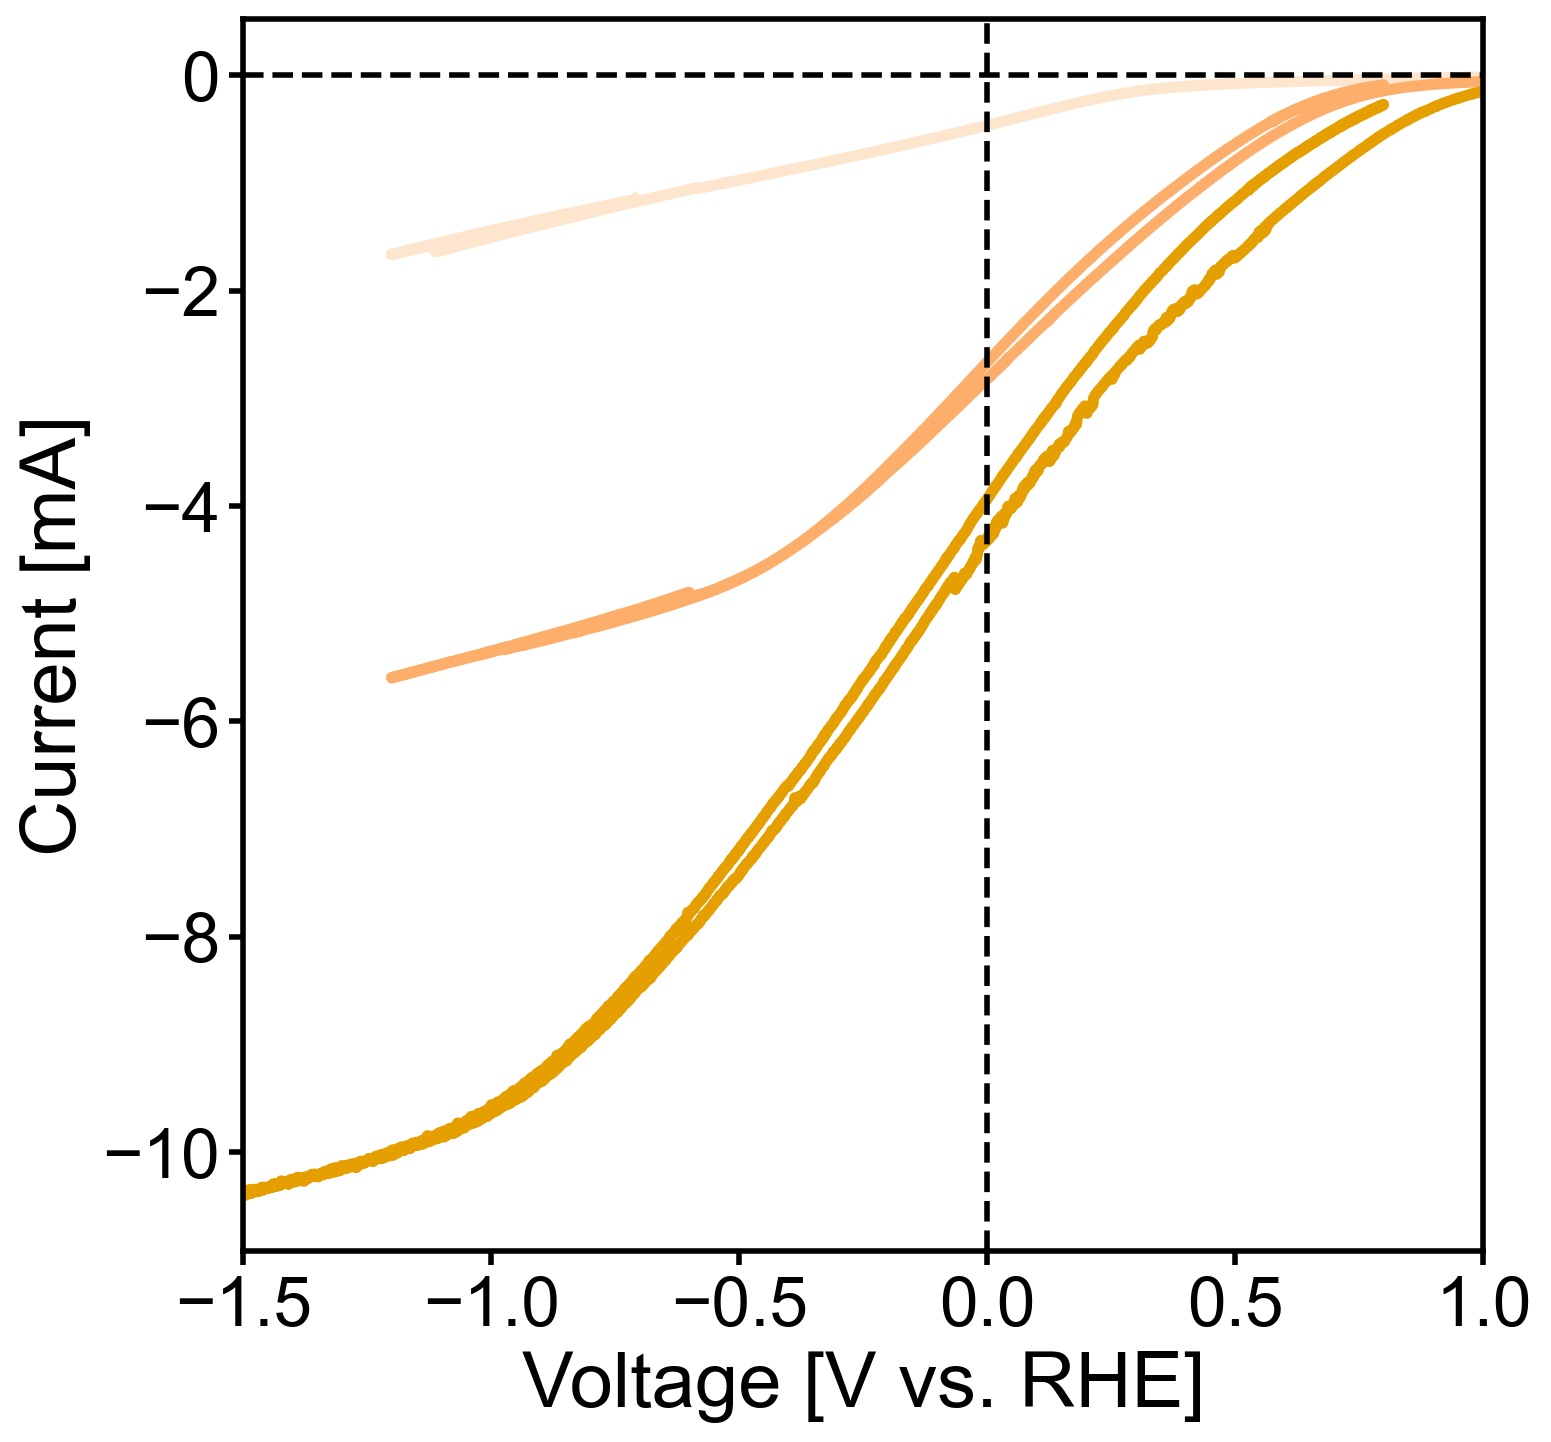

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt',
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt'
]
labels = ['0.1 Sun', '0.5 Sun', '1 Sun']
colors = ['#1D4499', "#1f77b4", "#2ca02c"]
colors = ['#FEE6CE','#FDAE6B','#E69F00']
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V']+refi, df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. RHE]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.xlim(-1.5,1)
#plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-0.9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-0, color='k', linestyle='--', linewidth=2)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()


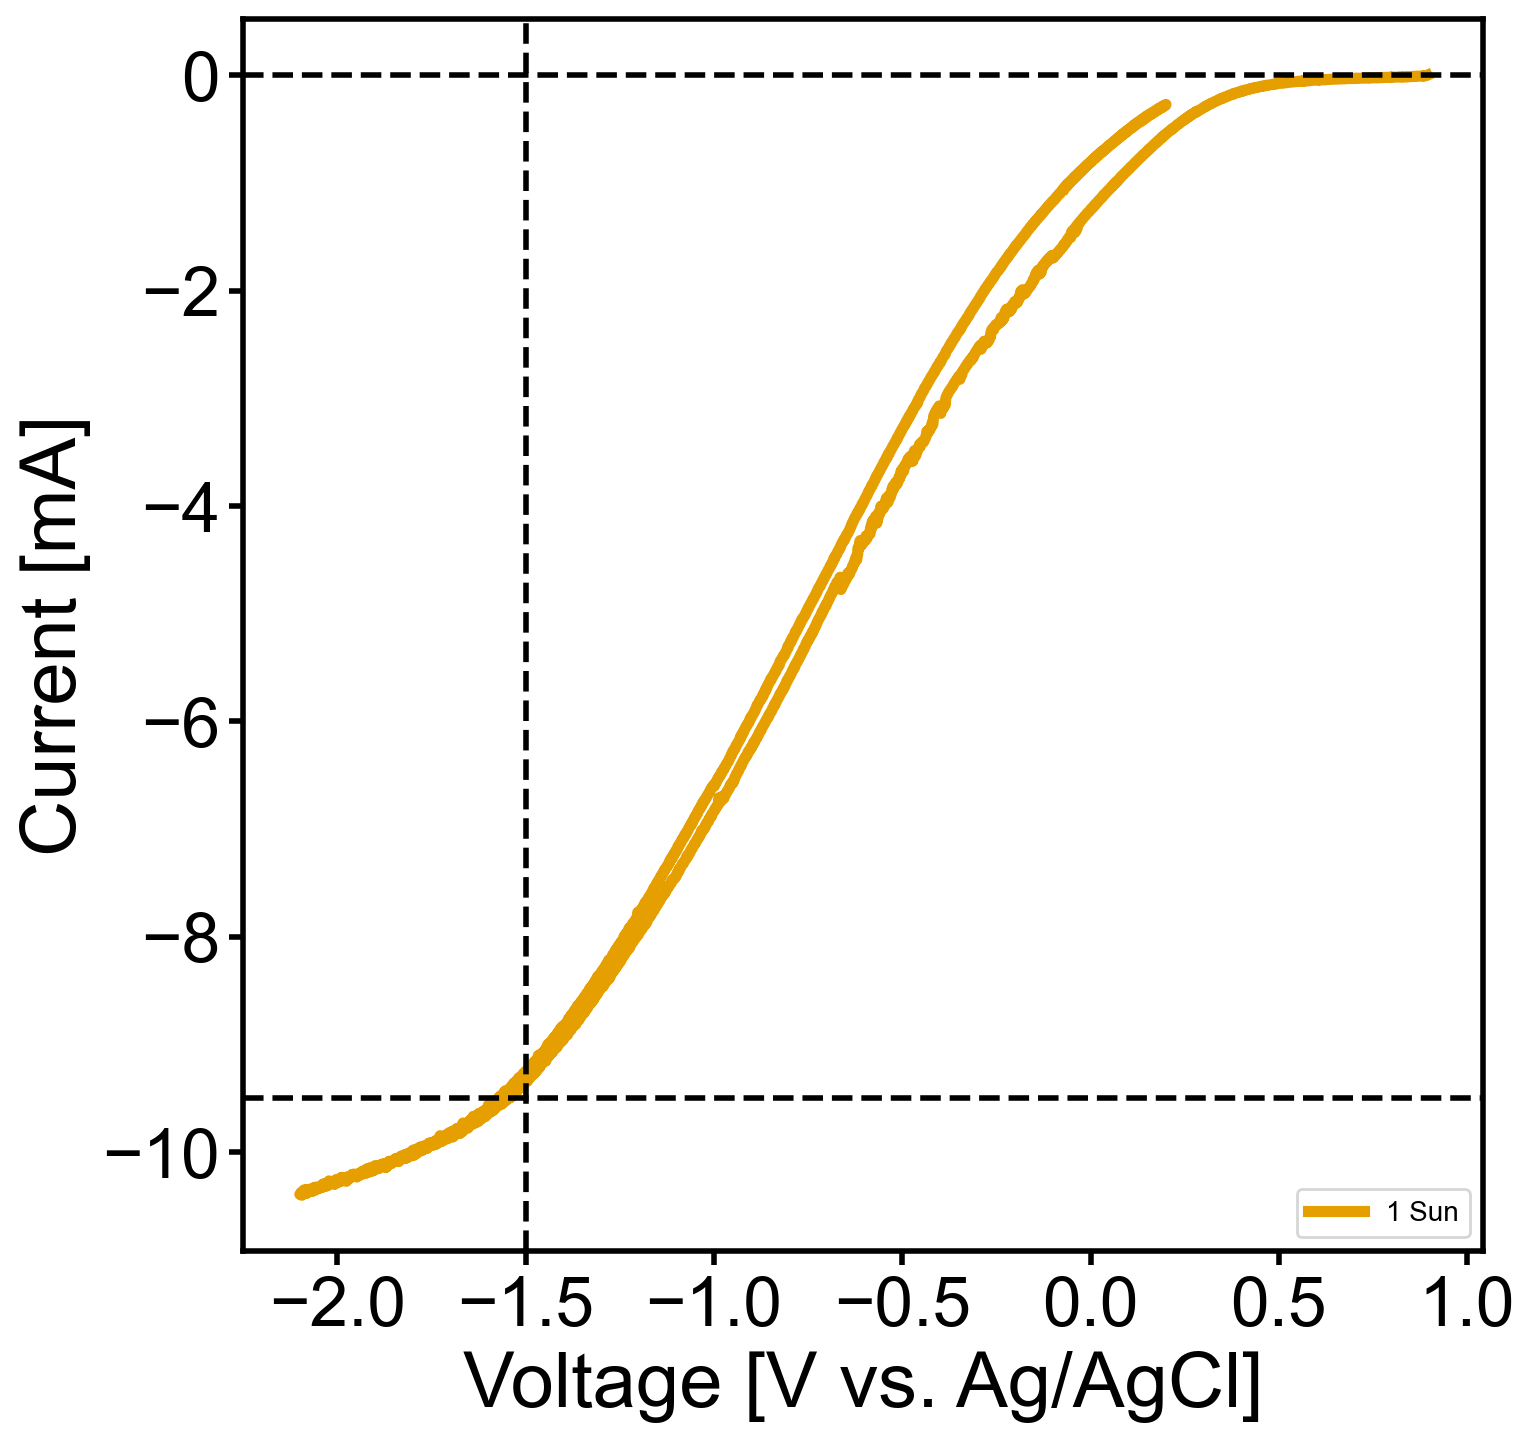

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt'
]
labels = [ '1 Sun']
colors = ['#1D4499', "#1f77b4", "#2ca02c"]
colors = ['#E69F00']

# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V'], df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. Ag/AgCl]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
plt.axhline(y=-9.5, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-1.5, color='k', linestyle='--', linewidth=2)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()

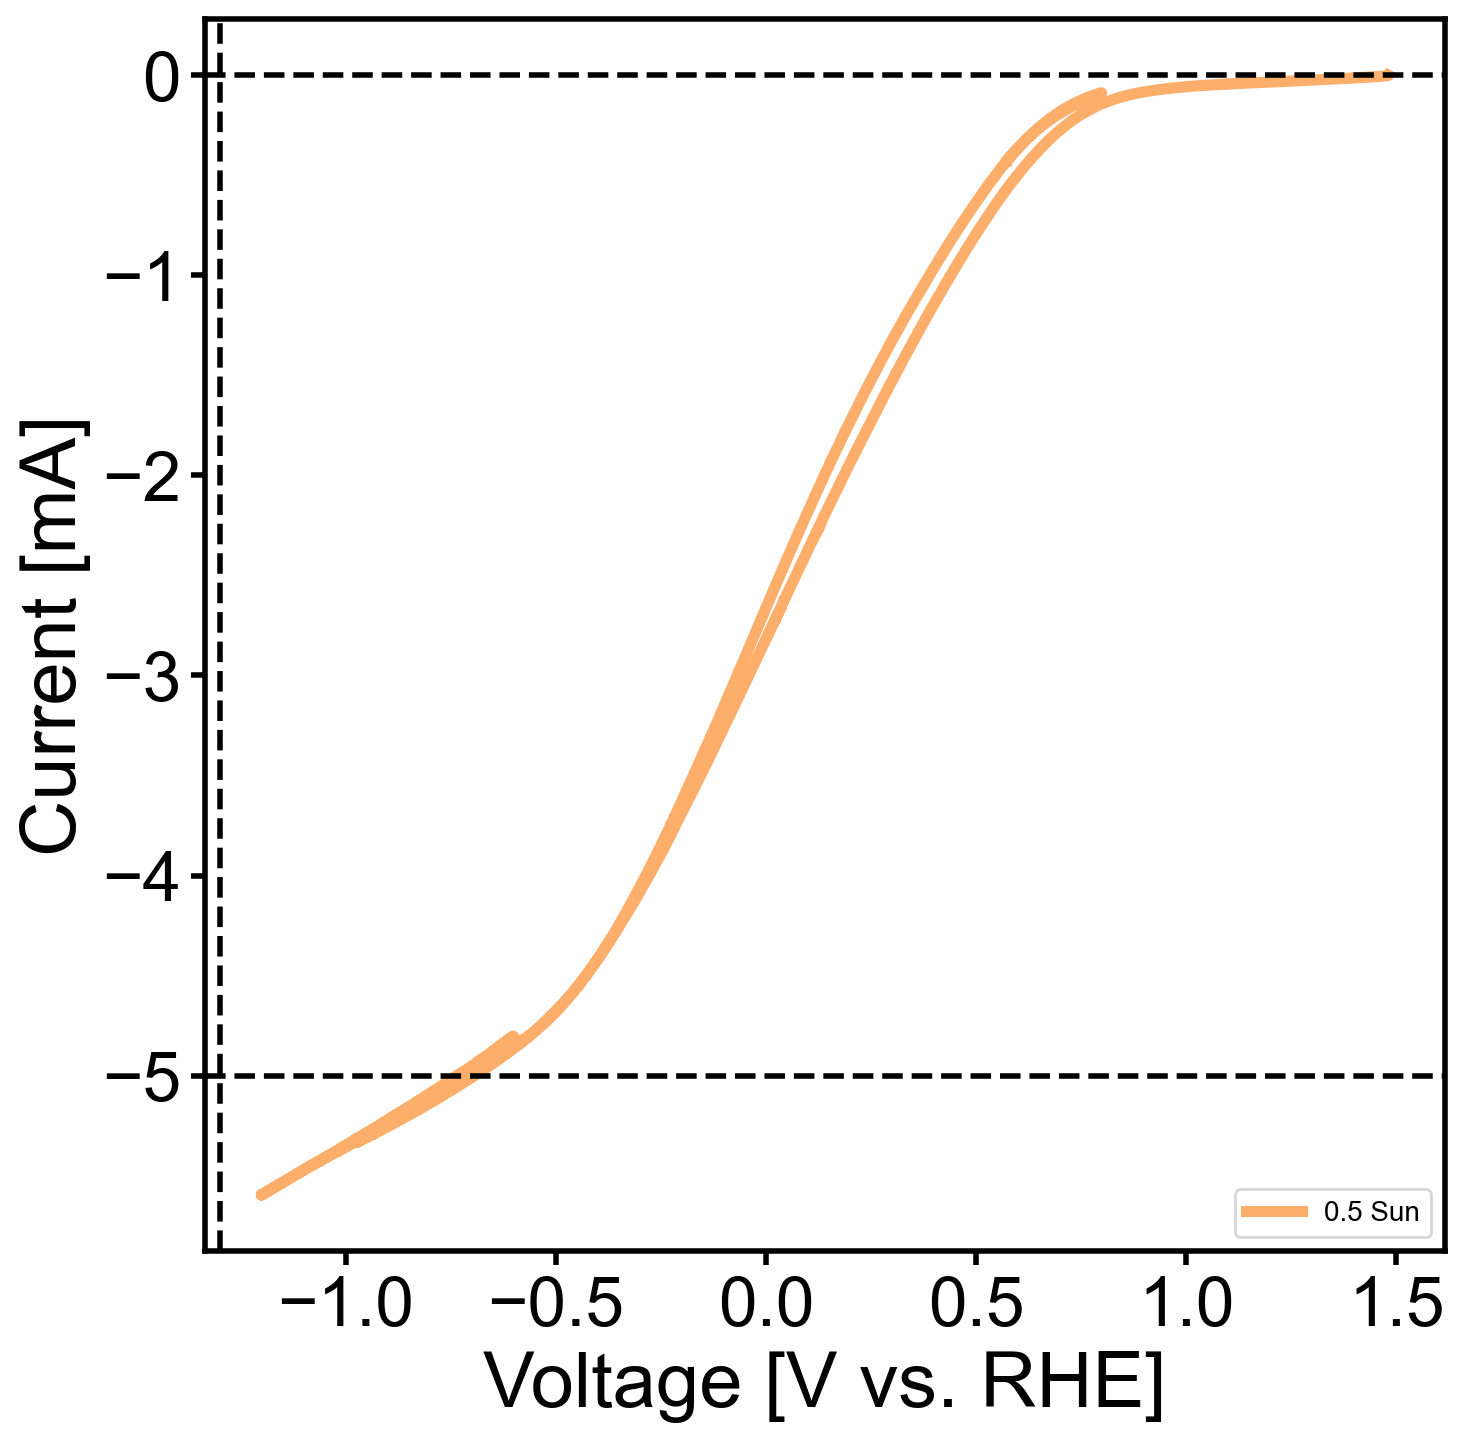

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
   '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt',
]
labels = [ '0.5 Sun']
colors = ['#FDAE6B',]
##colors = ['#E69F00']

# Set up the static figure
plt.figure(figsize=(8, 8))
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V']+refi, df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. RHE]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
plt.axhline(y=-5, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-1.3, color='k', linestyle='--', linewidth=2)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()

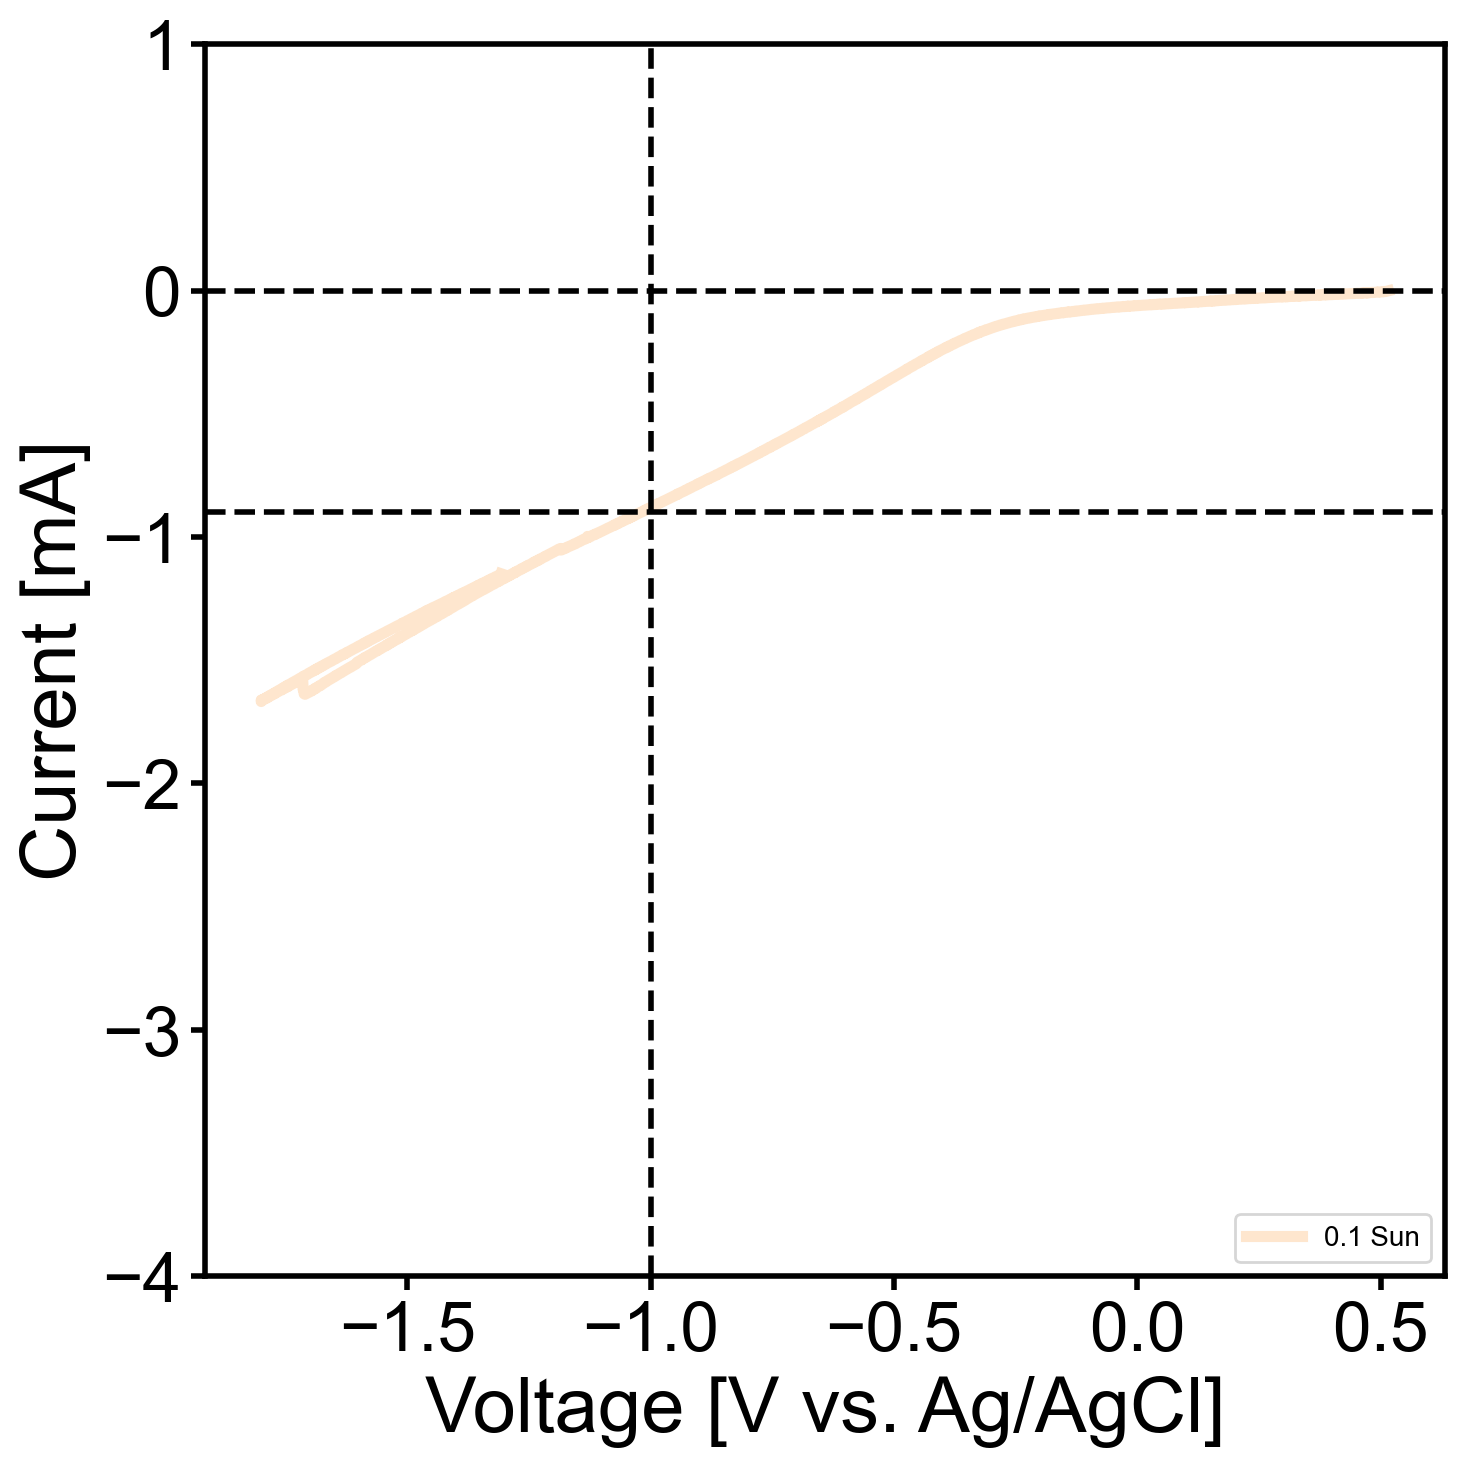

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
]
labels = [ '0.1 Sun']
colors = ['#FEE6CE',]
##colors = ['#E69F00']

# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V'], df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. Ag/AgCl]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
plt.axhline(y=-0.9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-1, color='k', linestyle='--', linewidth=2)
plt.ylim(-4,1)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()

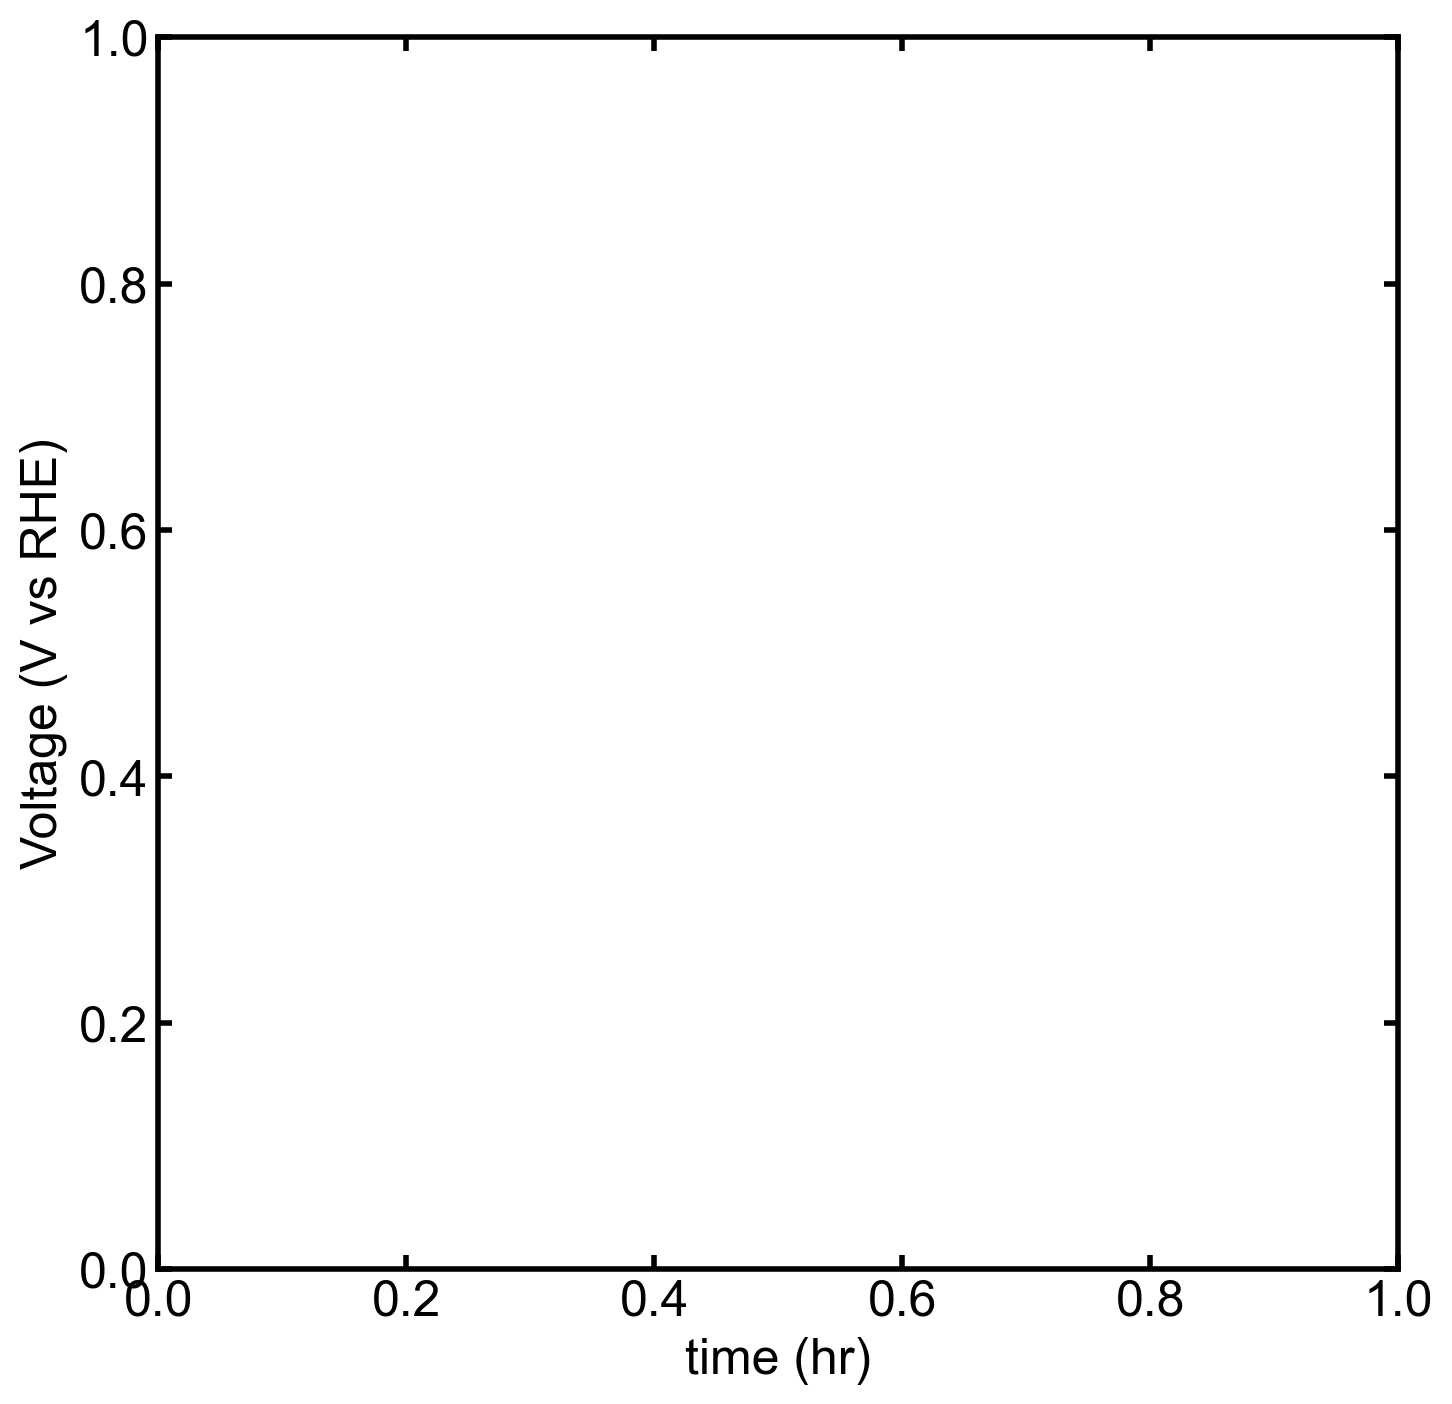

In [10]:
filelist = [


]
#setting our figure size
plt.figure(figsize=(8,8))
plt.grid(False)
#now lets set our color scheme for plotting data up
#cmap = sns.color_palette(sns.color_palette('Blues'))+sns.color_palette(sns.color_palette('winter'));del cmap[0]
#lot of good options here I like Dark2, Set1, Set2, hsl; but can search for 'python color palettes and find w/e'

#most of the time we probably want to shift the potential to RHE, we can do that here
ref = 0.197     #standard reference electrode potential for w/e ref is used
pH =  6.8  #just pH of the solution
refi = ref + 0.059*pH  #units in volts
skippi = [66,72,63,63]
timei=[0,1,2,3,4,5,6,7,8,9,10,11,12]
cmap = [ "#9467bd",'b', 'g', 'm', 'c', 'y']



# Initialize independent time offset trackers for each sequence
offset_group1 = 0.0  # For the 2, 3, 4 sequence
offset_group2 = 0.0  # For the 5, 6 sequence

# Define the two separate sequential groups
group1_indices = [2, 3, 4]
group2_indices = [5, 6]

# Map your legend labels directly to each file index.
# We use '_nolegend_' for the continuation files so they don't duplicate.
plot_labels_2 = [
    '-5 mA light FR',      # File 0
    '-1 mA dark FZ',      # File 1
    '-5mA light FR',   # File 2 (Start of Group 1)
    '-1mA FR dark',   # File 5 (Start of Group 2)
    'OCV Dark',           # File 7
    '5 hr',               # File 8
    '6 hr',               # File 9
    '24 hr'               # File 10 (Add more if needed)
]

for jj in range(len(filelist)):
    # Read the file with correct headers depending on index
    if jj < 7:
        df = pd.read_csv(filelist[jj], skiprows=56, encoding="ISO-8859-1", delimiter='\t')
    else:
        df = pd.read_csv(filelist[jj], skiprows=46, encoding="ISO-8859-1", delimiter='\t')
    
    # Convert raw seconds to hours
    current_time_hours = df['time/s'] / 3600
    
    # Determine which timeline to align this file to
    if jj in group1_indices:
        # Align to the 2, 3, 4 timeline
        x_values = current_time_hours + offset_group1
        offset_group1 += current_time_hours.max()
        
    elif jj in group2_indices:
        # Align to the separate 5, 6 timeline
        x_values = current_time_hours + offset_group2
        offset_group2 += current_time_hours.max()
        
    else:
        # All other files start plotting from 0
        x_values = current_time_hours

    # Fetch the correct label for this index
    current_label = plot_labels_2[jj]

    # Plot the line
    plt.plot(x_values, df['<Ewe/V>'], color=cmap[jj], linewidth=2.0, label=current_label)

plt.tick_params(axis='both', right=True,top=True, direction = 'in',width = 2, length = 5)
#plt.xticks(np.arange(0,0.6,0.2),fontsize=9) #can also define interval of ticks here with [] like [1,2,3,4,5,6],fontsize
#plt.yticks(np.arange(-12,1.5,2),fontsize=9)

#meant = [0.5,1.5,2.5,3.5,4.5,5.5]
#plt.plot(meant,meanj,marker = 'o',c='k',ms=10,mew=2,lw=3)

# plt.title('FZ in the dark',fontsize = 28)
ax = plt.gca()
#plt.legend(labels)
#plt.ylim(-1.2, -0.9)
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)

ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)
#setting up the xaxis and yaxis naming and size
plt.xlabel('time (hr)',fontsize=18) 
plt.ylabel('Voltage (V vs RHE)',fontsize=18)  #if in uA can use unicode \u03BC 
# plt.xticks(fontsize=26,c=cmap3[jj]) #can also define interval of ticks here with [] like [1,2,3,4,5,6],fontsize
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend()
plt.show()

Filtering out data points outside the range: -10.0V to 2.0V
Reading file '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt', skipping 0 header lines.
An error occurred while processing '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt': Expected 1 fields in line 16, saw 2
Reading file '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C02.mpt', skipping 48 header lines.


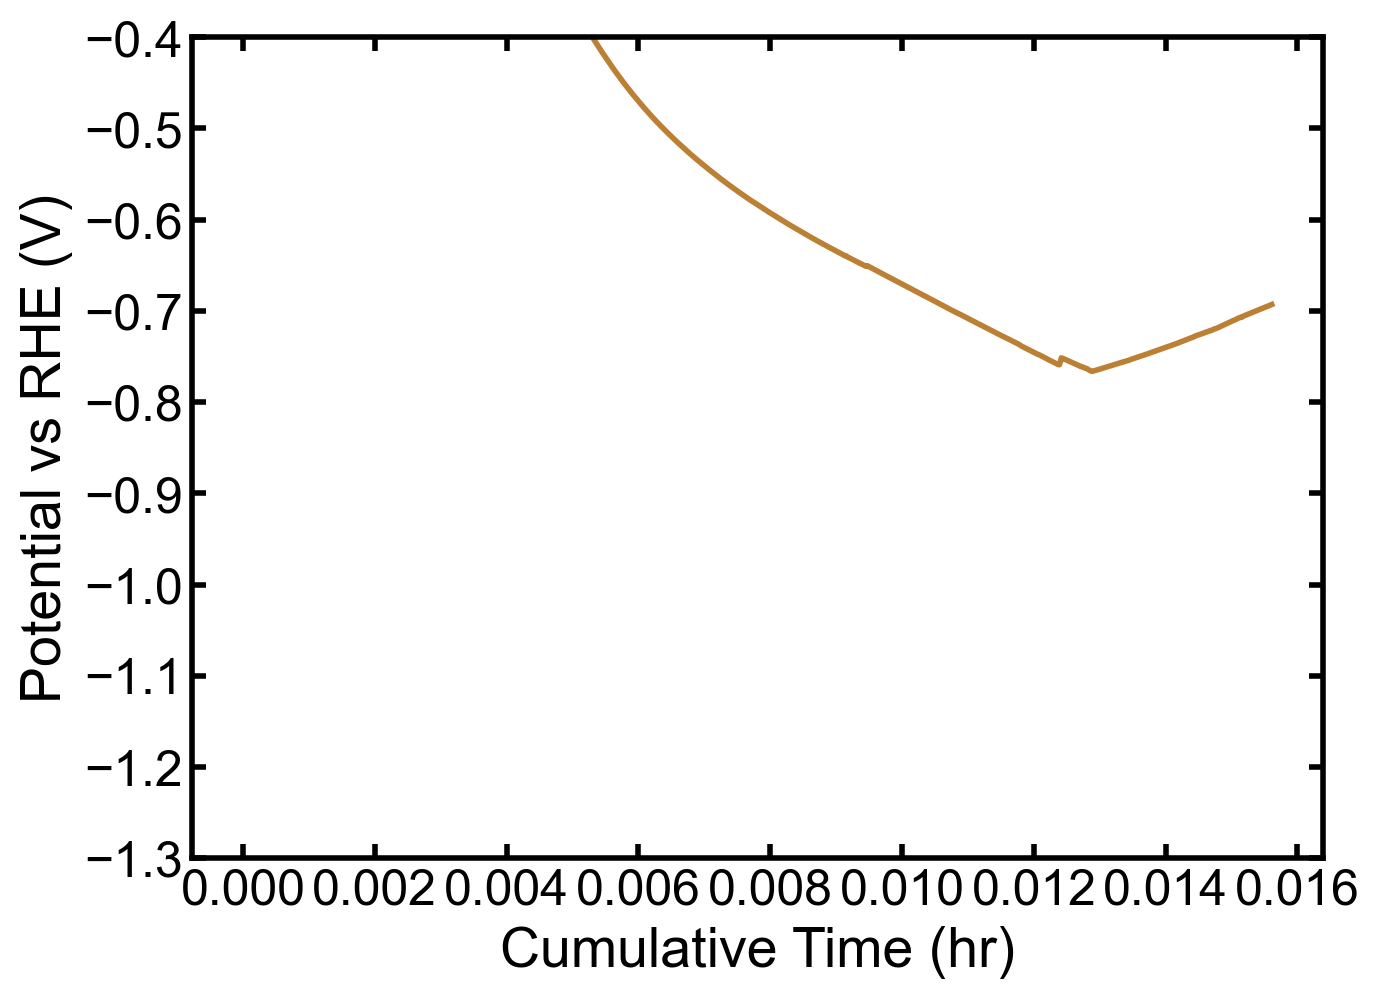

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def find_skiprows(filename, encoding="ISO-8859-1"):
    """
    Find the number of rows to skip by locating the header line.
    The header line is assumed to contain 'time/s' and '<Ewe/V>'.
    """
    with open(filename, 'r', encoding=encoding) as f:
        for i, line in enumerate(f):
            if 'time/s' in line and '<Ewe/V>' in line:
                return i
    return 0 # Default to 0 if header not found

# --- File List & Parameters ---
# IMPORTANT: Make sure these files exist in the same directory as the script,
# or provide the full path to them.
filelist0p1sun = [
'20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_0p1sun_CPs_2_C01.mpt',
 '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_0p1sun_CPs_2_C02.mpt',
]

VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 2.0
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
cmap = ["#ffdd32", "#bc8034"]
plot_labels = ['gold', 'copper']

# --- Plotting Setup ---
plt.figure(figsize=(7, 5))
plt.grid(False)
print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

# --- Plotting Loop ---
cumulative_time_offset = 0.0
for jj, filepath in enumerate(filelist0p1sun):
    if not os.path.exists(filepath):
        print(f"Error: The file '{filepath}' was not found. Skipping.")
        continue

    # Dynamically find the number of rows to skip
    skip = find_skiprows(filepath)
    print(f"Reading file '{filepath}', skipping {skip} header lines.")

    # Read data and filter
    try:
        df = pd.read_csv(filepath, skiprows=skip, encoding="ISO-8859-1", delimiter='\t', engine='python')
        
        # Defensive check for required columns
        if '<Ewe/V>' not in df.columns or 'time/s' not in df.columns:
            print(f"Warning: Missing required columns in '{filepath}'. Skipping.")
            continue

        df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()

        if not df_filtered.empty:
            # Calculate time for plotting
            df_filtered['plot_time_hr'] = (df_filtered['time/s'] / 3600) + cumulative_time_offset
            
            # Plot data
            current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj+1}'
            plt.plot(df_filtered['plot_time_hr'], df_filtered['<Ewe/V>'] + refi, color=cmap[jj % len(cmap)], linewidth=2.0, label=current_label)
            
            # Update time offset for the next file
#            cumulative_time_offset = df_filtered['plot_time_hr'].max()
        else:
            print(f"Warning: No data left in '{filepath}' after filtering. Check voltage range and file content.")
            
    except Exception as e:
        print(f"An error occurred while processing '{filepath}': {e}")


# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=20)
plt.ylabel('Potential vs RHE (V)', fontsize=20)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend()
plt.tight_layout()
plt.ylim(-1.3, -0.4)

# Save the figure and show the plot
plt.savefig("zoomed_voltage_after_ocv.pdf", format="pdf", bbox_inches="tight")
plt.show()




Filtering out data points outside the range: -10.0V to 2.0V
Error: The file '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_0p5sun_CPs_C01.mpt' was not found. Skipping.
Error: The file '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_0p5sun_CPs_C02.mpt' was not found. Skipping.


/var/folders/v7/gxvkh6fs2bl1s2vfh9653l900000gr/T/ipykernel_35047/2356587163.py:87: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


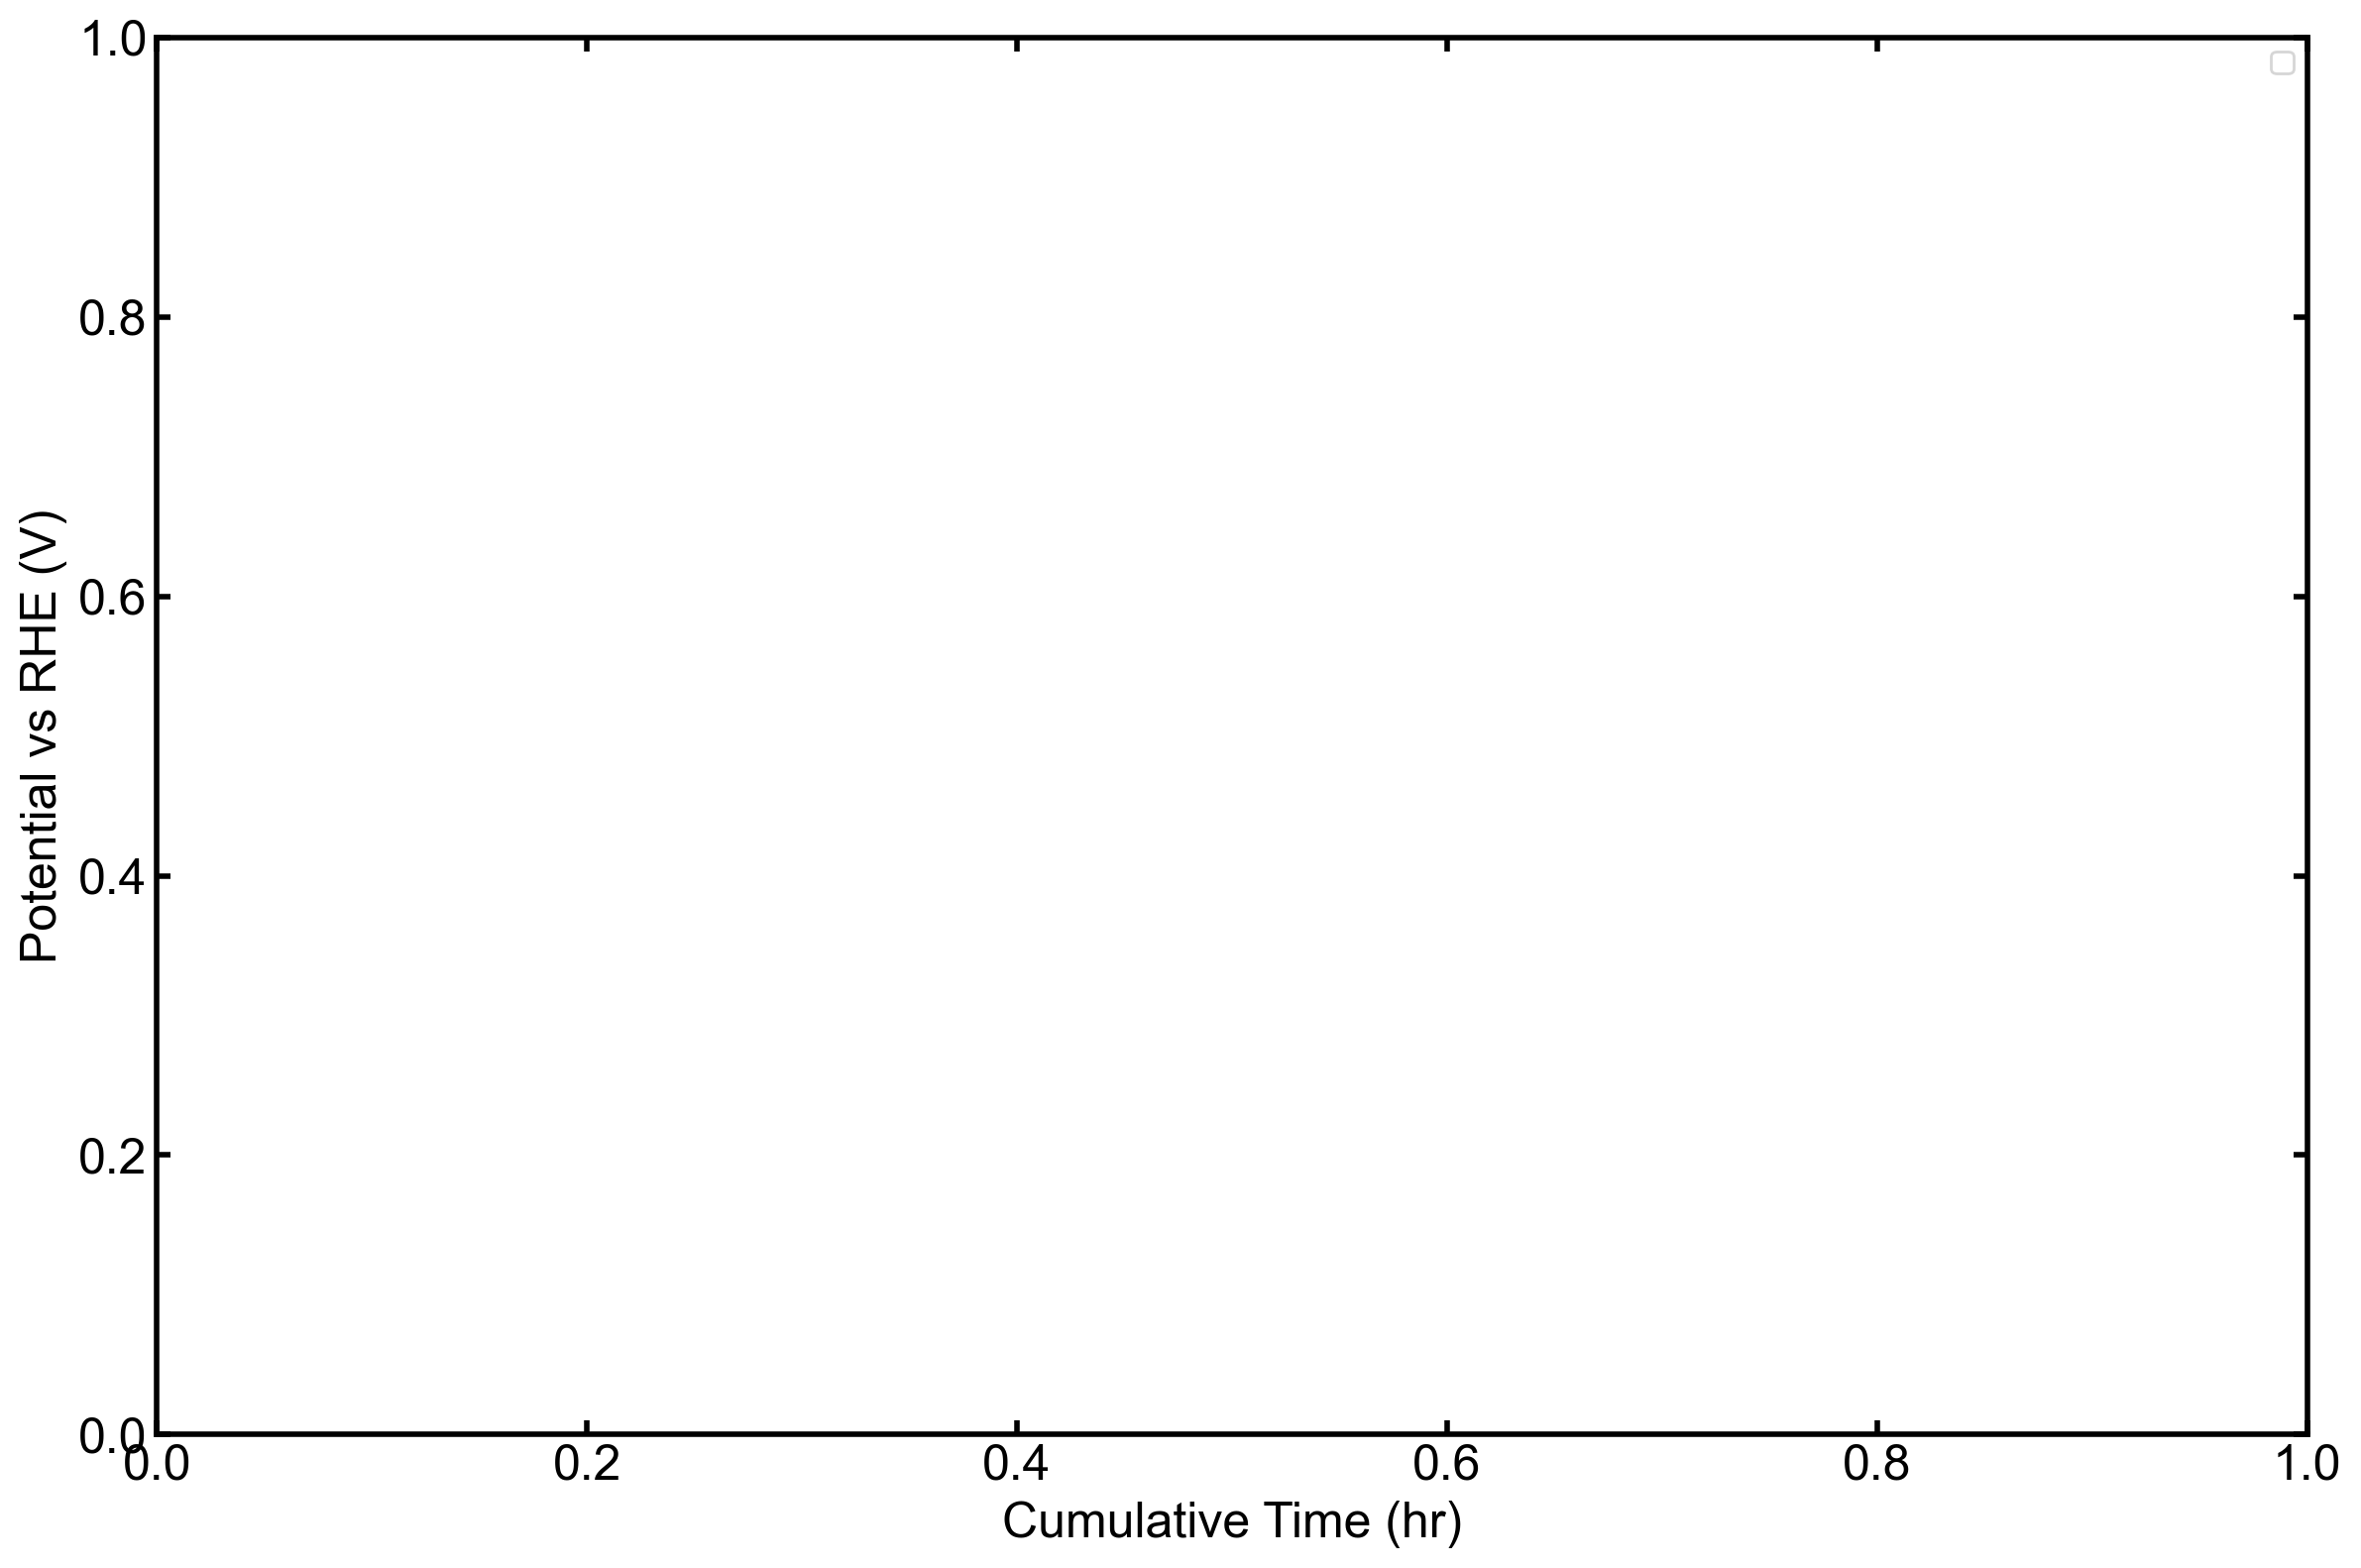

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def find_skiprows(filename, encoding="ISO-8859-1"):
    """
    Find the number of rows to skip by locating the header line.
    The header line is assumed to contain 'time/s' and '<Ewe/V>'.
    """
    with open(filename, 'r', encoding=encoding) as f:
        for i, line in enumerate(f):
            if 'time/s' in line and '<Ewe/V>' in line:
                return i
    return 0 # Default to 0 if header not found

# --- File List & Parameters ---
# IMPORTANT: Make sure these files exist in the same directory as the script,
# or provide the full path to them.
filelist0p1sun = [
 '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_0p5sun_CPs_C01.mpt',
 '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_0p5sun_CPs_C02.mpt',
]

VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 2.0
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
cmap = ["#ffdd32", "#bc8034"]
plot_labels = ['gold', 'copper']

# --- Plotting Setup ---
plt.figure(figsize=(12, 8))
plt.grid(False)
print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

# --- Plotting Loop ---
cumulative_time_offset = 0.0
for jj, filepath in enumerate(filelist0p1sun):
    if not os.path.exists(filepath):
        print(f"Error: The file '{filepath}' was not found. Skipping.")
        continue

    # Dynamically find the number of rows to skip
    skip = find_skiprows(filepath)
    print(f"Reading file '{filepath}', skipping {skip} header lines.")

    # Read data and filter
    try:
        df = pd.read_csv(filepath, skiprows=skip, encoding="ISO-8859-1", delimiter='\t', engine='python')
        
        # Defensive check for required columns
        if '<Ewe/V>' not in df.columns or 'time/s' not in df.columns:
            print(f"Warning: Missing required columns in '{filepath}'. Skipping.")
            continue

        df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()

        if not df_filtered.empty:
            # Calculate time for plotting
            df_filtered['plot_time_hr'] = (df_filtered['time/s'] / 3600) + cumulative_time_offset
            
            # Plot data
            current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj+1}'
            plt.plot(df_filtered['plot_time_hr'], df_filtered['<Ewe/V>'] + refi - 0.09, color=cmap[jj % len(cmap)], linewidth=2.0, label=current_label)
            
            # Update time offset for the next file
#            cumulative_time_offset = df_filtered['plot_time_hr'].max()
        else:
            print(f"Warning: No data left in '{filepath}' after filtering. Check voltage range and file content.")
            
    except Exception as e:
        print(f"An error occurred while processing '{filepath}': {e}")


# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
plt.legend()
plt.tight_layout()
#plt.ylim(-1.3, -0.4)

# Save the figure and show the plot
plt.savefig("zoomed_voltage_after_ocv.pdf", format="pdf", bbox_inches="tight")
plt.show()



Filtering out data points outside the range: -10.0V to 2.0V
Reading file '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_1sun_CPs_C01.mpt', skipping 56 header lines.
Reading file '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_1sun_CPs_C02.mpt', skipping 56 header lines.


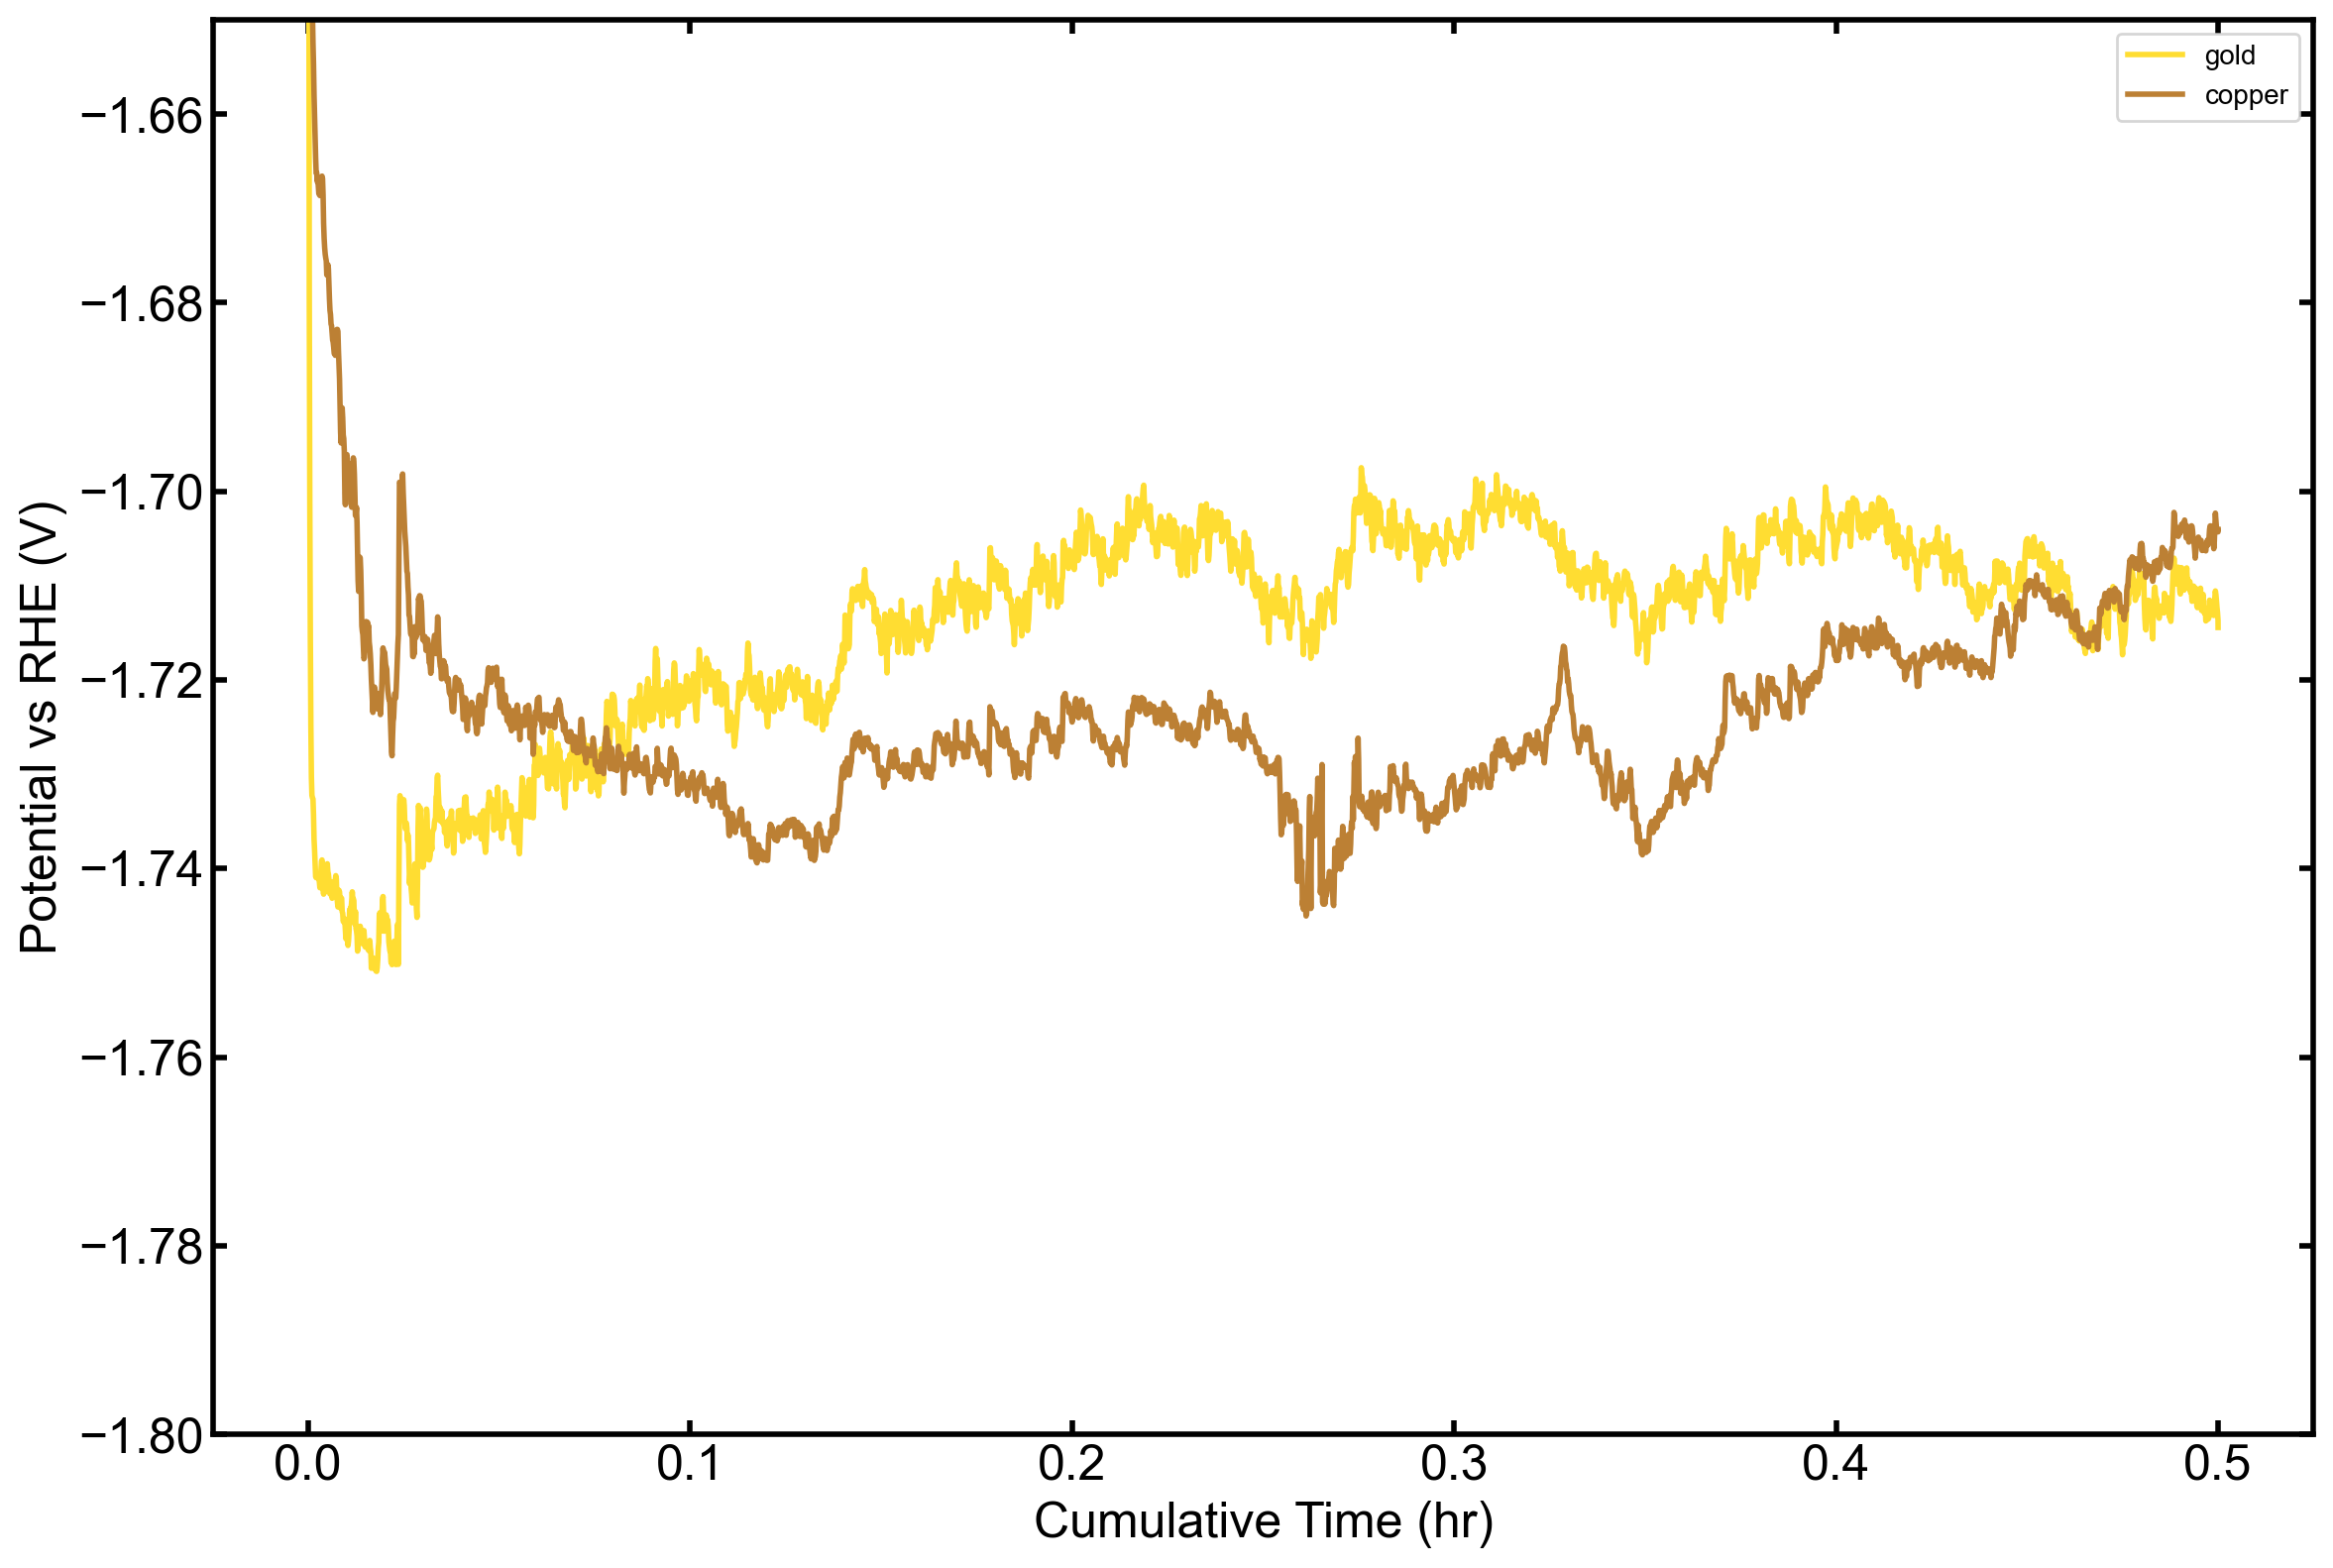

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def find_skiprows(filename, encoding="ISO-8859-1"):
    """
    Find the number of rows to skip by locating the header line.
    The header line is assumed to contain 'time/s' and '<Ewe/V>'.
    """
    with open(filename, 'r', encoding=encoding) as f:
        for i, line in enumerate(f):
            if 'time/s' in line and '<Ewe/V>' in line:
                return i
    return 0 # Default to 0 if header not found

# --- File List & Parameters ---
# IMPORTANT: Make sure these files exist in the same directory as the script,
# or provide the full path to them.
filelist0p1sun = [
'20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_1sun_CPs_C01.mpt',
 '20260810_3tt_interdigitatedmask_auonch1_cuonch2_darkelec_10mlmin_1sun_CPs_C02.mpt',]

VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 2.0
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
cmap = ["#ffdd32", "#bc8034"]
plot_labels = ['gold', 'copper']

# --- Plotting Setup ---
plt.figure(figsize=(12, 8))
plt.grid(False)
print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

# --- Plotting Loop ---
cumulative_time_offset = 0.0
for jj, filepath in enumerate(filelist0p1sun):
    if not os.path.exists(filepath):
        print(f"Error: The file '{filepath}' was not found. Skipping.")
        continue

    # Dynamically find the number of rows to skip
    skip = find_skiprows(filepath)
    print(f"Reading file '{filepath}', skipping {skip} header lines.")

    # Read data and filter
    try:
        df = pd.read_csv(filepath, skiprows=skip, encoding="ISO-8859-1", delimiter='\t', engine='python')
        
        # Defensive check for required columns
        if '<Ewe/V>' not in df.columns or 'time/s' not in df.columns:
            print(f"Warning: Missing required columns in '{filepath}'. Skipping.")
            continue

        df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()

        if not df_filtered.empty:
            # Calculate time for plotting
            df_filtered['plot_time_hr'] = (df_filtered['time/s'] / 3600) + cumulative_time_offset
            
            # Plot data
            current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj+1}'
            plt.plot(df_filtered['plot_time_hr'], df_filtered['<Ewe/V>'] + refi - 0.09, color=cmap[jj % len(cmap)], linewidth=2.0, label=current_label)
            
            # Update time offset for the next file
#            cumulative_time_offset = df_filtered['plot_time_hr'].max()
        else:
            print(f"Warning: No data left in '{filepath}' after filtering. Check voltage range and file content.")
            
    except Exception as e:
        print(f"An error occurred while processing '{filepath}': {e}")


# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
plt.legend()
plt.tight_layout()
plt.ylim(-1.8, -1.65)

# Save the figure and show the plot
plt.savefig("zoomed_voltage_after_ocv.pdf", format="pdf", bbox_inches="tight")
plt.show()